# Filtro di Kalman 2D (Multidimensionale)

Il **Filtro di Kalman multidimensionale** stima lo stato di un sistema dinamico lineare combinando un modello fisico di movimento (**Predict**) con le misurazioni effettuate da sensori rumorosi (**Update**).

A differenza del caso 1D, lo stato del sistema non è un singolo valore scalare $\mu$, ma un **vettore di stato** $\mathbf{x}$, e l'incertezza associata è descritta da una **matrice di covarianza** $\mathbf{P}$.

---

## 1. Vettori e Matrici del Sistema

* **Vettore di Stato ($\mathbf{x}$):** Contiene le variabili fisico-cinematiche da stimare al tempo $k$. Per un moto 1D con posizione $p$ e velocità $v$, lo stato è un vettore 2D:
  $$\mathbf{x} = \begin{bmatrix} p \\ v \end{bmatrix}$$

* **Matrice di Covarianza dello Stato ($\mathbf{P}$):** Esprime l'incertezza e la correlazione tra le variabili del vettore di stato:
  $$\mathbf{P} = \begin{bmatrix} \sigma_p^2 & \sigma_{pv} \\ \sigma_{vp} & \sigma_v^2 \end{bmatrix}$$

* **Matrice di Transizione dello Stato ($\mathbf{F}$):** Relaziona lo stato al tempo $k-1$ con lo stato al tempo $k$ (es. legge del moto $p_k = p_{k-1} + v_{k-1} \Delta t$):
  $$\mathbf{F} = \begin{bmatrix} 1 & \Delta t \\ 0 & 1 \end{bmatrix}$$

* **Vettore di Controllo ($\mathbf{u}$):** Rappresenta gli ingressi noti agiti sul sistema (es. accelerazioni o comandi di guida).

* **Matrice di Covarianza del Rumore di Processo ($\mathbf{Q}$):** Modella l'incertezza o le perturbazioni della fisica del sistema non considerate nel modello cinetico.

* **Matrice di Misura ($\mathbf{H}$):** Proietta lo stato reale $\mathbf{x}$ nello spazio delle misurazioni $\mathbf{z}$. Se si misura solo la posizione $p$:
  $$\mathbf{H} = \begin{bmatrix} 1 & 0 \end{bmatrix} \implies \mathbf{z} = \mathbf{H}\mathbf{x}$$

* **Matrice di Covarianza del Rumore di Misura ($\mathbf{R}$):** Rappresenta la varianza e la precisione dei sensori di misura.

---

## 2. Le Equazioni del Filtro di Kalman

### Fase 1: Predict (Time Update)
Proietta lo stato e la covarianza al tempo successivo $k$:
1. **Stima dello stato a priori:**
   $$\mathbf{x}_{\text{pred}} = \mathbf{F} \mathbf{x} + \mathbf{u}$$
2. **Covarianza a priori:**
   $$\mathbf{P}_{\text{pred}} = \mathbf{F} \mathbf{P} \mathbf{F}^T + \mathbf{Q}$$

### Fase 2: Update (Measurement Correction)
Corregge la stima a priori incorporando la nuova misurazione $\mathbf{z}_k$:
1. **Innovazione ($\mathbf{y}$):**
   $$\mathbf{y} = \mathbf{z} - \mathbf{H} \mathbf{x}_{\text{pred}}$$
2. **Covarianza dell'innovazione ($\mathbf{S}$):**
   $$\mathbf{S} = \mathbf{H} \mathbf{P}_{\text{pred}} \mathbf{H}^T + \mathbf{R}$$
3. **Guadagno di Kalman ($\mathbf{K}$):**
   $$\mathbf{K} = \mathbf{P}_{\text{pred}} \mathbf{H}^T \mathbf{S}^{-1}$$
4. **Stima dello stato a posteriori:**
   $$\mathbf{x}_{\text{new}} = \mathbf{x}_{\text{pred}} + \mathbf{K} \mathbf{y}$$
5. **Covarianza a posteriori:**
   $$\mathbf{P}_{\text{new}} = (\mathbf{I} - \mathbf{K} \mathbf{H}) \mathbf{P}_{\text{pred}}$$

In [55]:
from math import sqrt
import matplotlib.pyplot as plt
import numpy as np


class matrix:
  """Classe per le operazioni algebriche di base sulle matrici."""

  def __init__(self, value):
    self.value = value
    self.dimx = len(value)
    self.dimy = len(value[0]) if value != [[]] else 0

  def zero(self, dimx, dimy):
    if dimx < 1 or dimy < 1:
      raise ValueError('Dimensioni matrice non valide')
    self.dimx = dimx
    self.dimy = dimy
    self.value = [[0.0 for _ in range(dimy)] for _ in range(dimx)]

  def identity(self, dim):
    if dim < 1:
      raise ValueError('Dimensioni matrice non valide')
    self.dimx = dim
    self.dimy = dim
    self.value = [[0.0 for _ in range(dim)] for _ in range(dim)]
    for i in range(dim):
      self.value[i][i] = 1.0

  def __add__(self, other):
    if self.dimx != other.dimx or self.dimy != other.dimy:
      raise ValueError('Dimensioni non compatibili per la somma')
    res = matrix([[]])
    res.zero(self.dimx, self.dimy)
    for i in range(self.dimx):
      for j in range(self.dimy):
        res.value[i][j] = self.value[i][j] + other.value[i][j]
    return res

  def __sub__(self, other):
    if self.dimx != other.dimx or self.dimy != other.dimy:
      raise ValueError('Dimensioni non compatibili per la sottrazione')
    res = matrix([[]])
    res.zero(self.dimx, self.dimy)
    for i in range(self.dimx):
      for j in range(self.dimy):
        res.value[i][j] = self.value[i][j] - other.value[i][j]
    return res

  def __mul__(self, other):
    if self.dimy != other.dimx:
      raise ValueError('Dimensioni non compatibili per il prodotto')
    res = matrix([[]])
    res.zero(self.dimx, other.dimy)
    for i in range(self.dimx):
      for j in range(other.dimy):
        for k in range(self.dimy):
          res.value[i][j] += self.value[i][k] * other.value[k][j]
    return res

  def transpose(self):
    res = matrix([[]])
    res.zero(self.dimy, self.dimx)
    for i in range(self.dimx):
      for j in range(self.dimy):
        res.value[j][i] = self.value[i][j]
    return res

  def inverse(self):
    # Inversa robusta per matrici 1x1 e 2x2
    if self.dimx == 1 and self.dimy == 1:
      val = self.value[0][0]
      if abs(val) < 1e-12:
        raise ValueError('Matrice singolare o vicina a zero')
      return matrix([[1.0 / val]])
    if self.dimx == 2 and self.dimy == 2:
      det = (
          self.value[0][0] * self.value[1][1]
          - self.value[0][1] * self.value[1][0]
      )
      if abs(det) < 1e-12:
        raise ValueError('Matrice singolare')
      inv_det = 1.0 / det
      return matrix([
          [self.value[1][1] * inv_det, -self.value[0][1] * inv_det],
          [-self.value[1][0] * inv_det, self.value[0][0] * inv_det],
      ])
    return self.CholeskyInverse()

  def Cholesky(self, ztol=1.0e-5):
    res = matrix([[]])
    res.zero(self.dimx, self.dimx)
    for i in range(self.dimx):
      S = sum([(res.value[k][i]) ** 2 for k in range(i)])
      d = self.value[i][i] - S
      if abs(d) < ztol:
        res.value[i][i] = 0.0
      else:
        if d < 0.0:
          raise ValueError('Matrice non definita positiva')
        res.value[i][i] = sqrt(d)
      for j in range(i + 1, self.dimx):
        S = sum([res.value[k][i] * res.value[k][j] for k in range(i)])
        res.value[i][j] = (self.value[i][j] - S) / res.value[i][i]
    return res

  def CholeskyInverse(self):
    res = matrix([[]])
    res.zero(self.dimx, self.dimx)
    for j in reversed(range(self.dimx)):
      tjj = self.value[j][j]
      S = sum(
          [self.value[j][k] * res.value[j][k] for k in range(j + 1, self.dimx)]
      )
      res.value[j][j] = 1.0 / tjj**2 - S / tjj
      for i in reversed(range(j)):
        S = sum(
            [self.value[i][k] * res.value[k][j] for k in range(i + 1, self.dimx)]
        )
        res.value[i][j] = res.value[j][i] = -S / self.value[i][i]
    return res

  def __repr__(self):
    return repr(self.value)


# -----------------------------------------------------------------------------
# FILTRO DI KALMAN
# -----------------------------------------------------------------------------
def kalman_filter(measurements, x, P, F, H, R, Q, u=None):
  """Esegue il Filtro di Kalman 2D completo per una sequenza di misurazioni."""
  if u is None:
    u = matrix([[0.0], [0.0]])
  I = matrix([[1.0, 0.0], [0.0, 1.0]])

  positions = []
  velocities = []
  uncertainties = []
  measurements_used = []

  for z_val in measurements:
    if z_val is not None:
      # --- Update  ---
      Z = matrix([[float(z_val)]])
      y = Z - (H * x)
      S = H * P * H.transpose() + R
      K = P * H.transpose() * S.inverse()
      x = x + (K * y)
      P = (I - (K * H)) * P
      measurements_used.append(float(z_val))
    else:
      # --- Prediction ---
      measurements_used.append(np.nan)

    positions.append(x.value[0][0])
    velocities.append(x.value[1][0])
    uncertainties.append(P.value[0][0])

    # --- Predict (Predizione) ---
    x = (F * x) + u
    P = F * P * F.transpose() + Q

  return {
      'x': x,
      'P': P,
      'positions': positions,
      'velocities': velocities,
      'uncertainties': uncertainties,
      'measurements_used': measurements_used,
  }


# -----------------------------------------------------------------------------
# FUNZIONE DI VISUALIZZAZIONE GRAFICA
# -----------------------------------------------------------------------------
def plot_kalman_results(title, res):
  """Genera 3 grafici: Posizione, Velocità e Incertezza nel tempo."""
  meas = res['measurements_used']
  pos = res['positions']
  vel = res['velocities']
  unc = res['uncertainties']
  t = range(1, len(pos) + 1)

  fig, axs = plt.subplots(3, 1, figsize=(10, 9))

  # 1. Posizione
  axs[0].scatter(
      t, meas, color='red', s=60, zorder=3, label='Misurazioni sensore ($z$)'
  )
  axs[0].plot(
      t, pos, 'b-o', linewidth=2, zorder=2, label='Stima Kalman (Posizione)'
  )
  axs[0].set_title(f'{title} — Posizione', fontsize=12)
  axs[0].set_ylabel('Posizione')
  axs[0].legend(loc='upper left')
  axs[0].grid(True, linestyle='--', alpha=0.6)

  # 2. Velocità
  axs[1].plot(t, vel, 'g-s', linewidth=2, label='Stima Velocità ($v$)')
  axs[1].set_title(f'{title} — Velocità Nascosta', fontsize=12)
  axs[1].set_ylabel('Velocità')
  axs[1].legend(loc='upper left')
  axs[1].grid(True, linestyle='--', alpha=0.6)

  # 3. Incertezza
  axs[2].plot(
      t, unc, 'm*-', linewidth=2, label='Incertezza sulla Posizione P[0,0]'
  )
  axs[2].set_title(
      f"{title} — Evoluzione dell'Incertezza (Varianza)", fontsize=12
  )
  axs[2].set_xlabel('Passo Temporale')
  axs[2].set_ylabel('Varianza P[0,0]')
  axs[2].legend(loc='upper left')
  axs[2].grid(True, linestyle='--', alpha=0.6)

  plt.tight_layout()
  plt.show()

---

## Esempio 1: Tracciamento di Posizione e Velocità  ($\mathbf{x} = [p, v]^T$)

In questo esempio stimiamo la posizione $p$ e la velocità $v$ di un veicolo lungo una traiettoria rettilinea ($\Delta t = 1$).
* Il sensore fornisce unicamente la misurazione della **posizione**.
* Il filtro ricava la **velocità nascosta** attraverso le correlazioni modellate nelle matrici $\mathbf{F}$ e $\mathbf{P}$.

### Condizioni Iniziali
* **Stato Iniziale:** Posizione $= 0$, Velocità $= 0$ ($\mathbf{x}_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$)
* **Incertezza Iniziale ($\mathbf{P}_0$):** Elevata (es. $1000$ sui termini diagonali), ad indicare che non conosciamo lo stato iniziale con precisione.

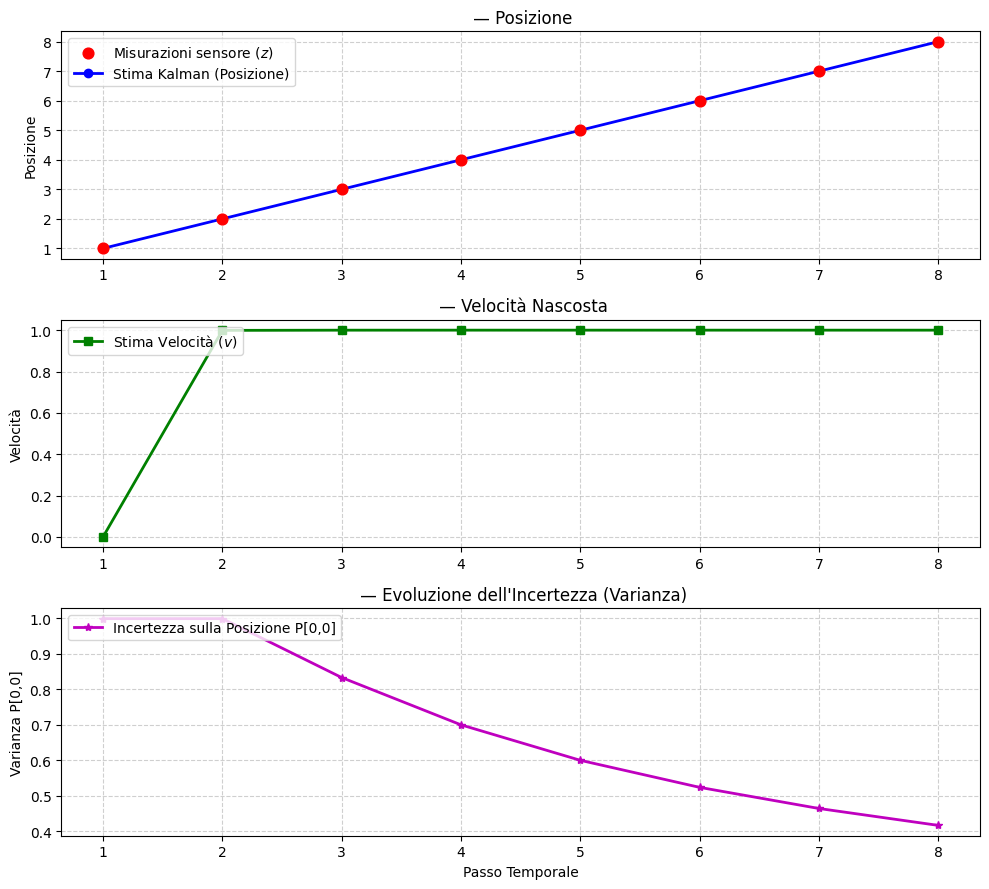

In [56]:
# ------------------------------------------
# Configurazione di Base
# ------------------------------------------
measurements = [1, 2, 3, 4, 5, 6, 7, 8]
x = matrix([[0.0], [0.0]])
P = matrix([[1000.0, 0.0], [0.0, 1000.0]])
u = matrix([[0.0], [0.0]])
F = matrix([[1.0, 1.0], [0.0, 1.0]])
H = matrix([[1.0, 0.0]])
R = matrix([[1.0]])
I = matrix([[1.0, 0.0], [0.0, 1.0]])
Q = matrix([[0.0, 0.0], [0.0, 0.0]])

res_R_high = kalman_filter(
    measurements,
    x,
    P,
    F,
    H,
    R,
    Q,
)
plot_kalman_results("", res_R_high)

---

## Esempio 2: Noisy Measurements (Sensibilità al Rumore di Misura $R$)

In questo scenario analizziamo l'effetto del rumore del sensore $R$ sul comportamento del filtro.
* **$R$ alto ($R = 5.0$):** Il filtro assume che il sensore sia inaffidabile. La traiettoria risulta smussata e cauta.
* **$R$ basso ($R = 0.1$):** Il filtro si fida cecamente delle misurazioni rumorose.

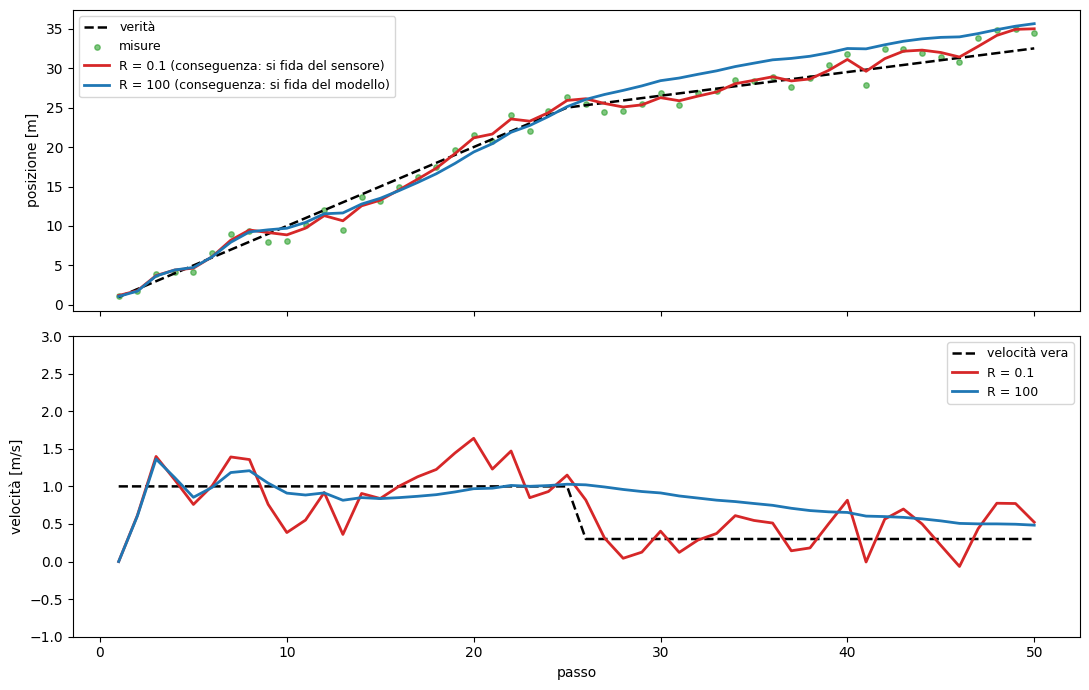

RMSE posizione  R = 0.1: 1.12 m   |   R = 100: 1.88 m


In [57]:
import numpy as np
import matplotlib.pyplot as plt

# --- Mondo simulato: 50 passi, rumore del sensore σ = 1.5 m, frenata a metà ---
rng = np.random.default_rng(0)
N = 50
v_true = np.where(np.arange(N) < 25, 1.0, 0.3)          # a t = 25 il veicolo rallenta
p_true = np.cumsum(v_true)
measurements_noisy = list(p_true + rng.normal(0, 1.5, N))

x_init = matrix([[0.0], [0.0]])
P_init = matrix([[1000.0, 0.0], [0.0, 1000.0]])
F = matrix([[1.0, 1.0], [0.0, 1.0]])
H = matrix([[1.0, 0.0]])
Q = matrix([[0.01, 0.0], [0.0, 0.01]])

res_R_high = kalman_filter(measurements_noisy, x_init, P_init, F, H, R=matrix([[100.0]]), Q=Q)
res_R_low  = kalman_filter(measurements_noisy, x_init, P_init, F, H, R=matrix([[0.1]]),  Q=Q)

# --- Confronto sullo stesso grafico ---
t = np.arange(1, N + 1)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(t, p_true, "k--", lw=1.8, label="verità")
axes[0].scatter(t, measurements_noisy, s=15, color="tab:green", alpha=0.6, label="misure")
axes[0].plot(t, res_R_low["positions"], color="tab:red", lw=2, label="R = 0.1 (conseguenza: si fida del sensore)")
axes[0].plot(t, res_R_high["positions"], color="tab:blue", lw=2, label="R = 100 (conseguenza: si fida del modello)")
axes[0].set_ylabel("posizione [m]"); axes[0].legend(fontsize=9)

axes[1].plot(t, v_true, "k--", lw=1.8, label="velocità vera")
axes[1].plot(t, res_R_low["velocities"], color="tab:red", lw=2, label="R = 0.1")
axes[1].plot(t, res_R_high["velocities"], color="tab:blue", lw=2, label="R = 100")
axes[1].set_ylabel("velocità [m/s]"); axes[1].set_xlabel("passo"); axes[1].set_ylim(-1, 3)
axes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

err = lambda r: np.sqrt(np.mean((np.array(r["positions"]) - p_true) ** 2))
print(f"RMSE posizione  R = 0.1: {err(res_R_low):.2f} m   |   R = 100: {err(res_R_high):.2f} m")

---

## Esempio 3: Process Noise ($Q$) — Gestione dell'Accelerazione

Il veicolo accelera ($p = 1, 3, 6, 10, 15, 21, \dots$), mentre il modello assume velocità costante ($\mathbf{F} = \begin{bmatrix} 1 & 1 \\ 0 & 1 \end{bmatrix}$).

* **$Q = 0$:** Il filtro assume un modello perfetto e accumula ritardo (*lag*).
* **$Q > 0$:** Il rumore di processo permette al filtro di adattarsi all'accelerazione non modellata.

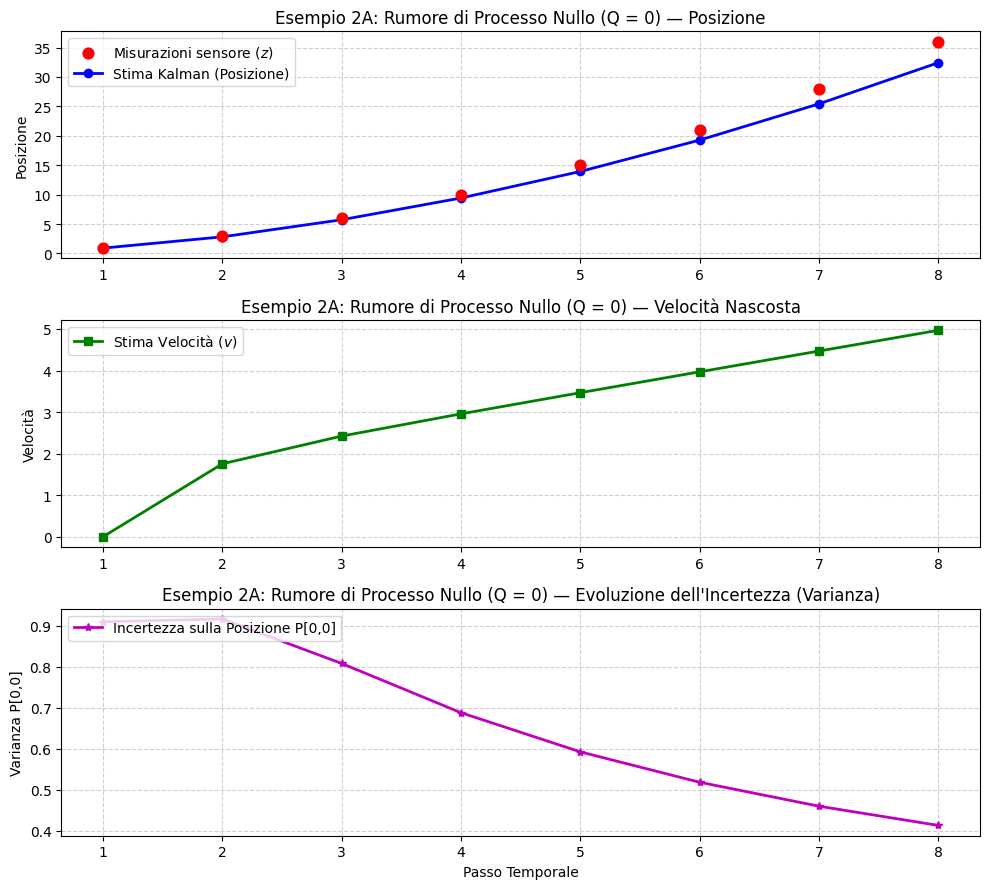

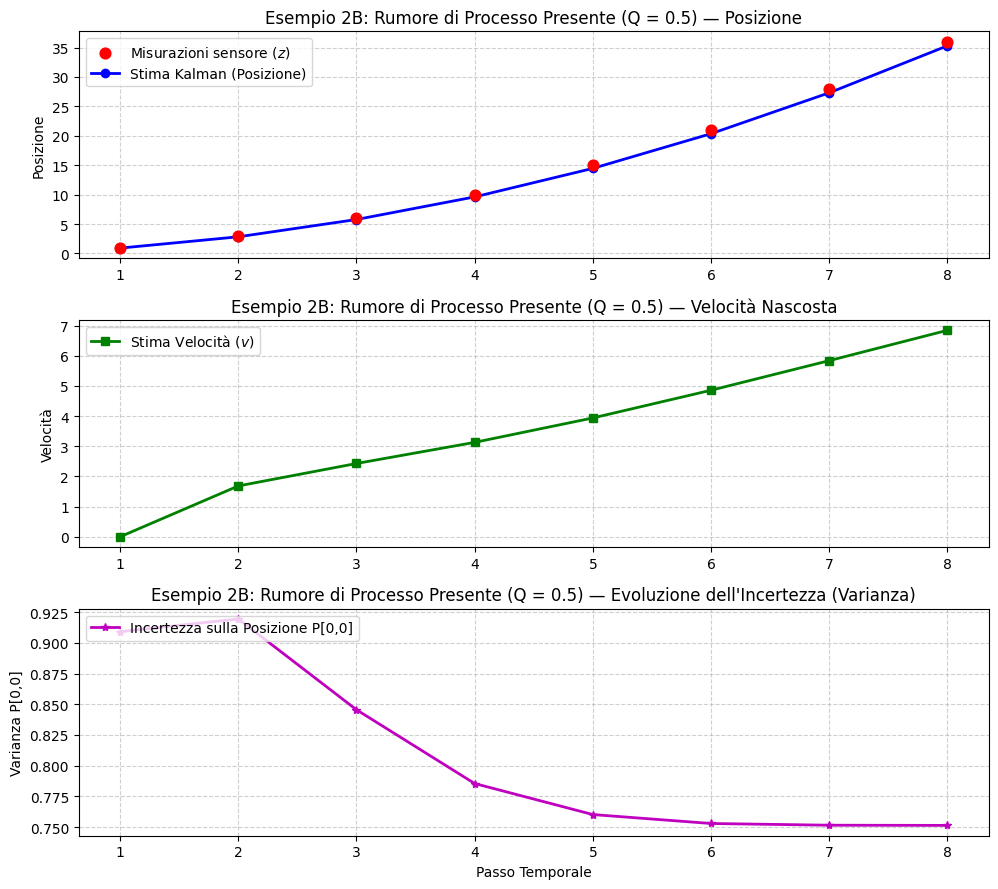

In [58]:
# --- Parametrizzazione Esempio 2 ---
measurements_acc = [1.0, 3.0, 6.0, 10.0, 15.0, 21.0, 28.0, 36.0]

x_init = matrix([[0.0], [0.0]])
P_init = matrix([[10.0, 0.0], [0.0, 10.0]])
F = matrix([[1.0, 1.0], [0.0, 1.0]])
H = matrix([[1.0, 0.0]])
R = matrix([[1.0]])

# Caso Q = 0 (Ignora l'accelerazione)
res_Q_zero = kalman_filter(
    measurements_acc,
    x_init,
    P_init,
    F,
    H,
    R,
    Q=matrix([[0.0, 0.0], [0.0, 0.0]]),
)
plot_kalman_results("Esempio 2A: Rumore di Processo Nullo (Q = 0)", res_Q_zero)

# Caso Q > 0 (Si adatta all'accelerazione)
res_Q_high = kalman_filter(
    measurements_acc,
    x_init,
    P_init,
    F,
    H,
    R,
    Q=matrix([[0.5, 0.0], [0.0, 0.5]]),
)
plot_kalman_results(
    "Esempio 2B: Rumore di Processo Presente (Q = 0.5)", res_Q_high
)

---

## Esempio 4: Convergenza da Elevata Incertezza Iniziale ($\mathbf{P}_0$ grande)

Il sistema parte da $p \approx 10$, ma il filtro ipotizza $\mathbf{x}_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$ con incertezza $\mathbf{P}_0 = 10000 \cdot \mathbf{I}$.
Grazie al guadagno di Kalman iniziale $\mathbf{K} \approx 1$, la stima converge immediatamente fin dal primo passo.

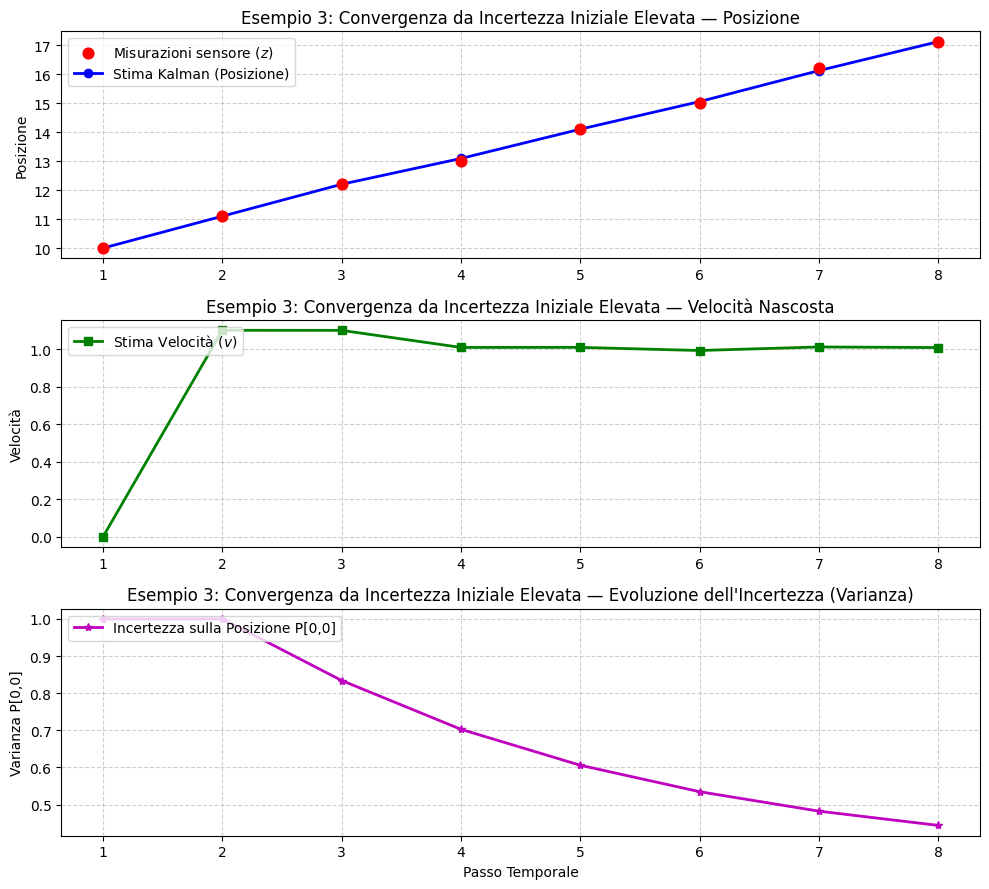

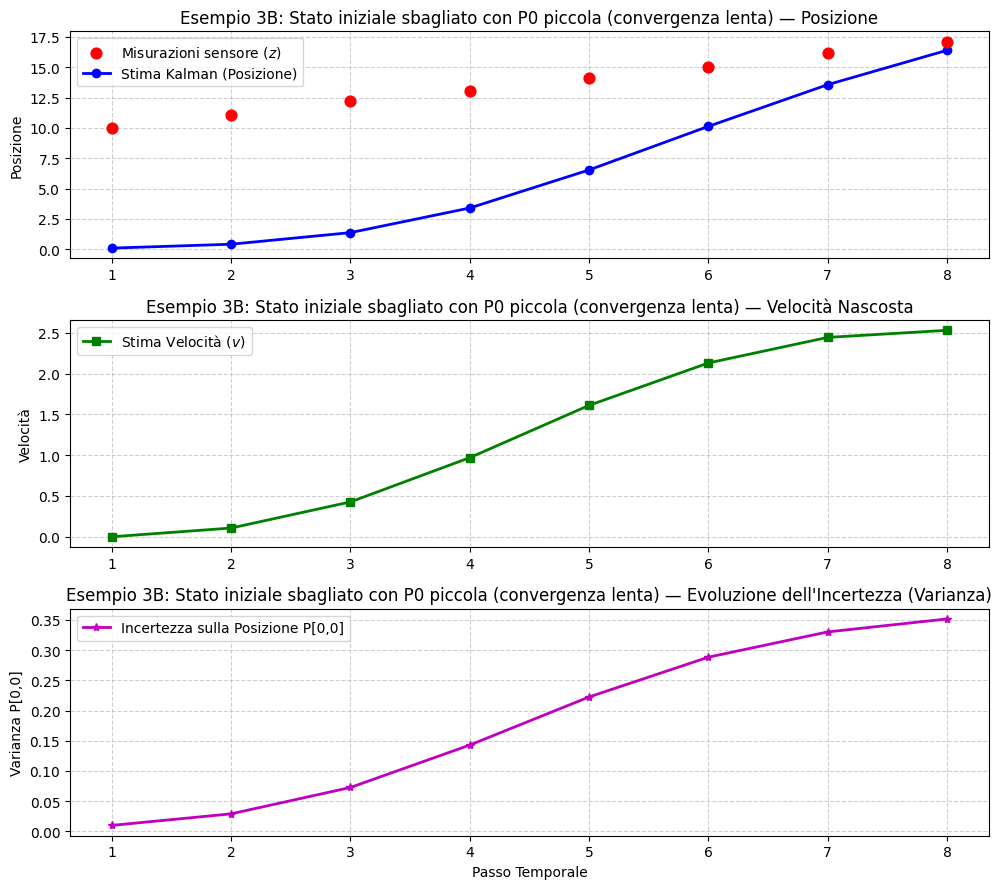

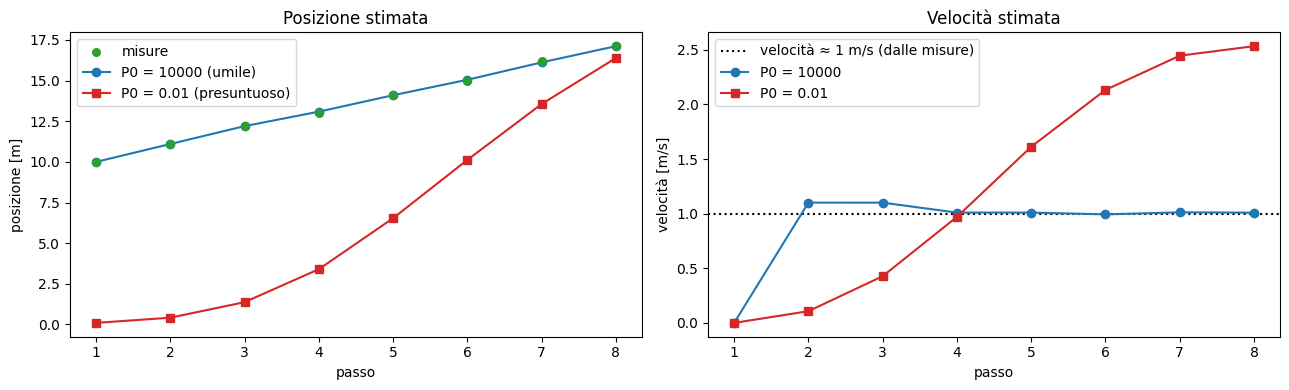

In [59]:
# --- Parametrizzazione Esempio 3 ---
measurements_far = [10.0, 11.1, 12.2, 13.0, 14.1, 15.0, 16.2, 17.1]

x_err = matrix([[0.0], [0.0]])
P_huge = matrix([[10000.0, 0.0], [0.0, 10000.0]])
F = matrix([[1.0, 1.0], [0.0, 1.0]])
H = matrix([[1.0, 0.0]])
R = matrix([[1.0]])
Q = matrix([[0.01, 0.0], [0.0, 0.01]])

res_p0_huge = kalman_filter(measurements_far, x_err, P_huge, F, H, R, Q)
plot_kalman_results(
    "Esempio 3: Convergenza da Incertezza Iniziale Elevata", res_p0_huge
)

# --- Esempio 3B: stato iniziale sbagliato ma P0 piccola (filtro "presuntuoso") ---
P_tiny = matrix([[0.01, 0.0], [0.0, 0.01]])

res_p0_tiny = kalman_filter(measurements_far, x_err, P_tiny, F, H, R, Q)
plot_kalman_results(
    "Esempio 3B: Stato iniziale sbagliato con P0 piccola (convergenza lenta)", res_p0_tiny
)

# --- Confronto diretto sullo stesso grafico ---
import numpy as np
import matplotlib.pyplot as plt

t = np.arange(1, len(measurements_far) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(t, measurements_far, color="tab:green", s=30, label="misure", zorder=3)
axes[0].plot(t, res_p0_huge["positions"], "o-", color="tab:blue", label="P0 = 10000 (umile)")
axes[0].plot(t, res_p0_tiny["positions"], "s-", color="tab:red", label="P0 = 0.01 (presuntuoso)")
axes[0].set_title("Posizione stimata"); axes[0].set_xlabel("passo"); axes[0].set_ylabel("posizione [m]")
axes[0].legend()
axes[1].axhline(1.0, color="black", ls=":", label="velocità ≈ 1 m/s (dalle misure)")
axes[1].plot(t, res_p0_huge["velocities"], "o-", color="tab:blue", label="P0 = 10000")
axes[1].plot(t, res_p0_tiny["velocities"], "s-", color="tab:red", label="P0 = 0.01")
axes[1].set_title("Velocità stimata"); axes[1].set_xlabel("passo"); axes[1].set_ylabel("velocità [m/s]")
axes[1].legend()
plt.tight_layout(); plt.show()

## Esempio 5: Inversione Improvvisa del Moto (Random Walk / Model Mismatch)

Il veicolo avanza fino a $5.0$ e poi inverte improvvisamente marcia verso $1.0$.
* **Con $Q$ piccolo ($Q = 0.001$):** L'inerzia numerica ritarda l'inversione della velocità stimata.
* **Con $Q$ adattativo ($Q = 0.5$):** Il filtro riaggancia prontamente la nuova direzione.

Ricorda che Q models l'incertezza dovuta al sistema o errori randomici

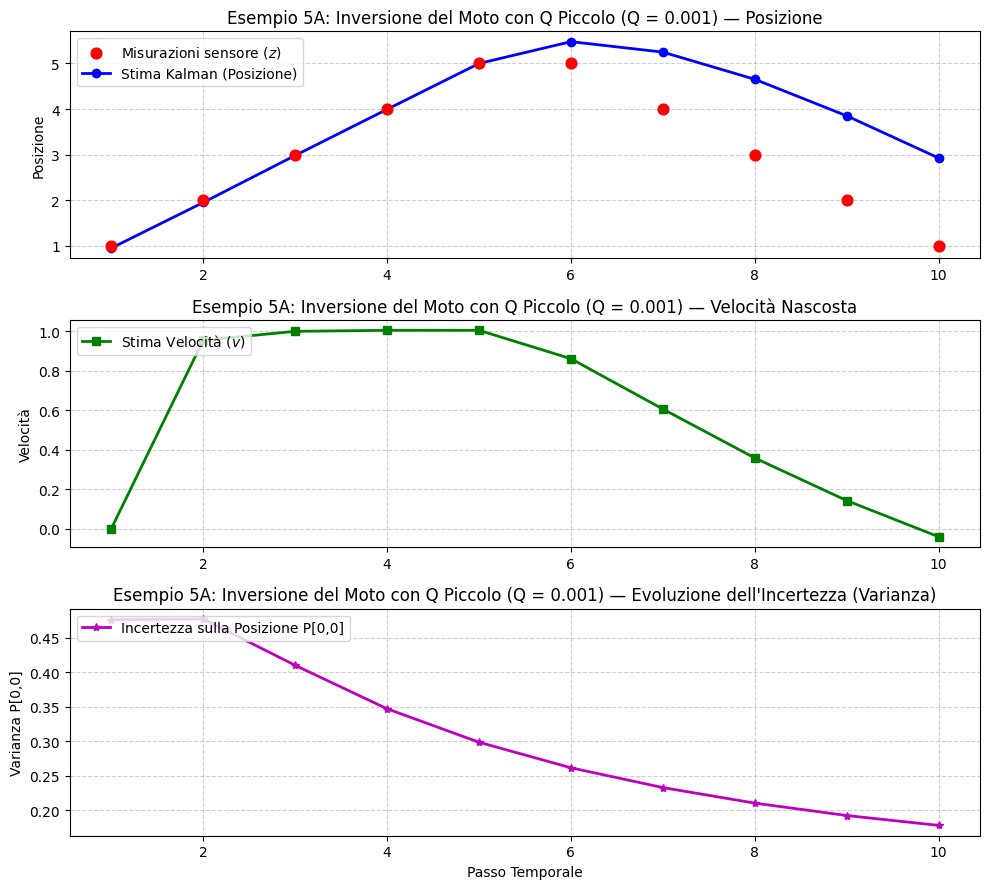

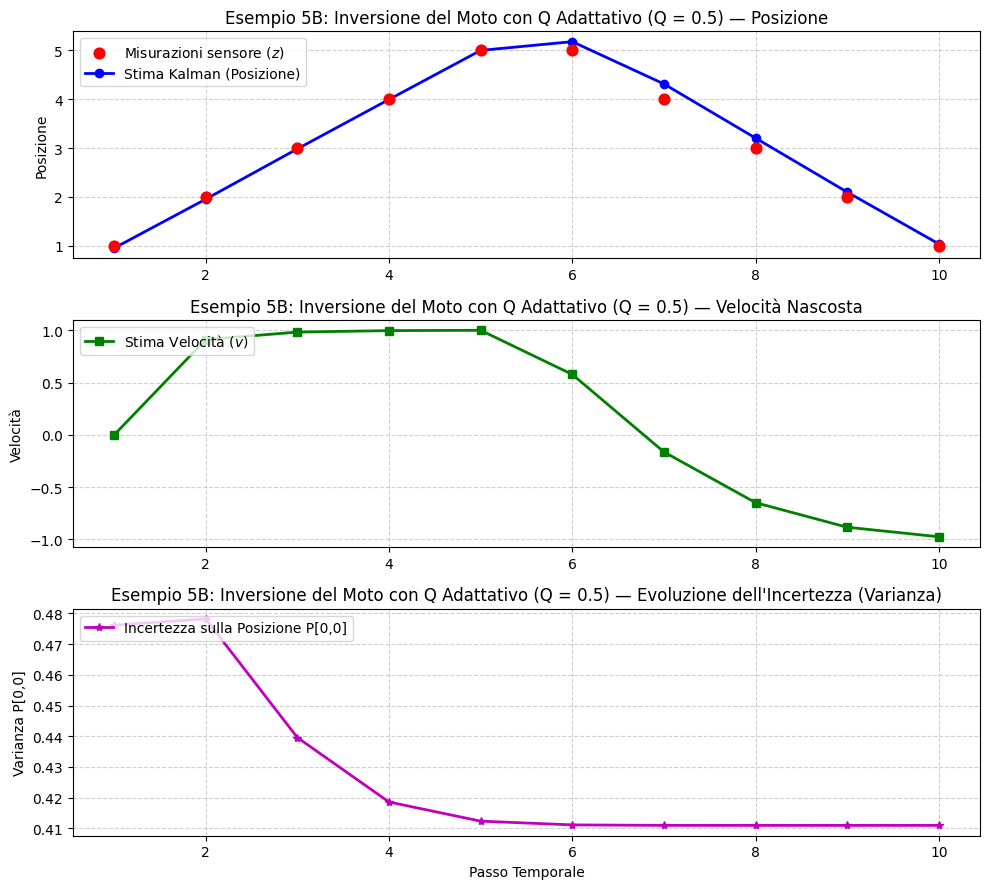

In [60]:
# --- Parametrizzazione Esempio 5 ---
measurements_rw = [1.0, 2.0, 3.0, 4.0, 5.0, 5.0, 4.0, 3.0, 2.0, 1.0]

F = matrix([[1.0, 1.0], [0.0, 1.0]])
H = matrix([[1.0, 0.0]])
R = matrix([[0.5]])
x_init = matrix([[0.0], [0.0]])
P_init = matrix([[10.0, 0.0], [0.0, 10.0]])

# Q Piccolo
res_rw_small = kalman_filter(
    measurements_rw,
    x_init,
    P_init,
    F,
    H,
    R,
    Q=matrix([[0.001, 0.0], [0.0, 0.001]]),
)
plot_kalman_results(
    "Esempio 5A: Inversione del Moto con Q Piccolo (Q = 0.001)", res_rw_small
)

# Q Adattativo
res_rw_adapt = kalman_filter(
    measurements_rw,
    x_init,
    P_init,
    F,
    H,
    R,
    Q=matrix([[0.5, 0.0], [0.0, 0.5]]),
)
plot_kalman_results(
    "Esempio 5B: Inversione del Moto con Q Adattativo (Q = 0.5)", res_rw_adapt
)

---

## Esempio 6: Gestione delle Misurazioni Mancanti (Missing Data)

Quando una misurazione è assente (`None`), il filtro esegue solo la fase di **Predict**, continuando a stimare lo stato e aumentando temporaneamente la varianza $\mathbf{P}$.

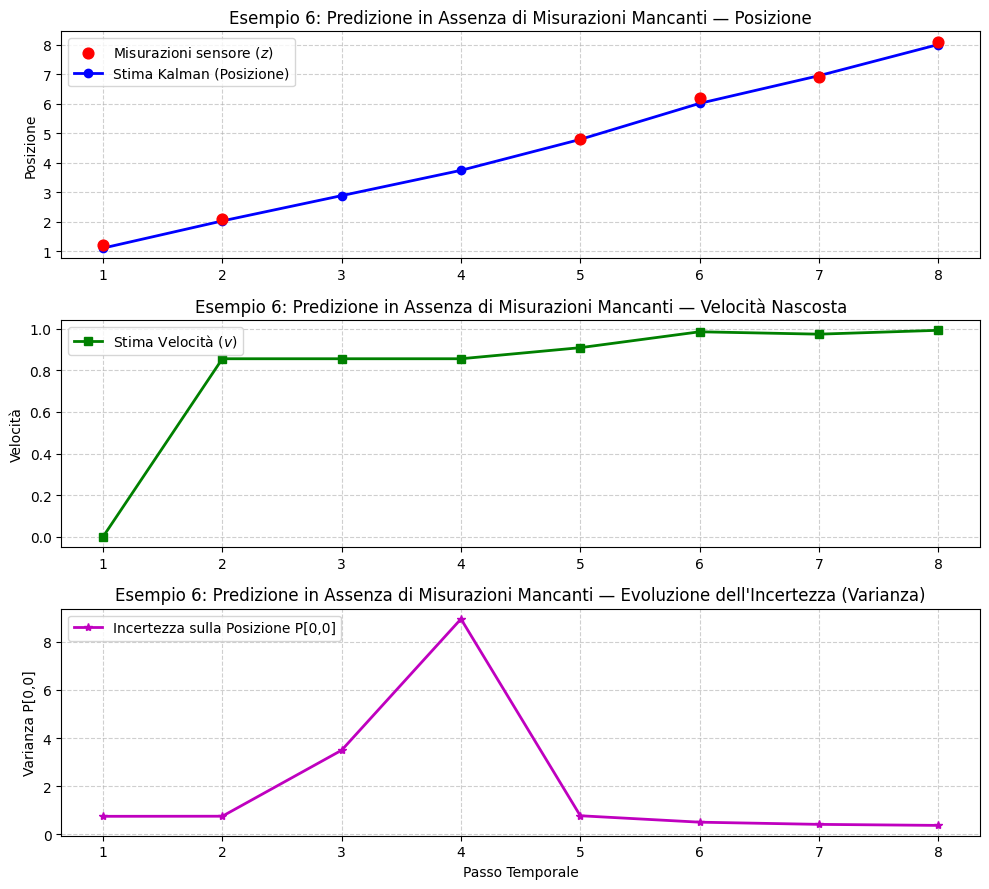

In [61]:
# --- Parametrizzazione Esempio 6 ---
measurements_missing = [1.2, 2.1, None, None, 4.8, 6.2, 6.9, 8.1]

x_init = matrix([[0.0], [0.0]])
P_init = matrix([[10.0, 0.0], [0.0, 10.0]])
F = matrix([[1.0, 1.0], [0.0, 1.0]])
H = matrix([[1.0, 0.0]])
R = matrix([[0.8]])
Q = matrix([[0.01, 0.0], [0.0, 0.01]])

res_missing = kalman_filter(
    measurements_missing, x_init, P_init, F, H, R, Q
)
plot_kalman_results(
    "Esempio 6: Predizione in Assenza di Misurazioni Mancanti", res_missing
)

---

## Esempio 7: Simulazione con Ground Truth

### Obiettivo
Valutare quantitativamente le prestazioni del Filtro di Kalman confrontando la stima con la **traiettoria reale (Ground Truth)** e verificando la consistenza statistica dell'incertezza dichiarata ($\pm 2\sigma$).

### Scenario
Generiamo una traiettoria reale di 60 passi in cui il veicolo parte da $p_0 = 0.0$ e $v_0 = 1.0$, ed è soggetto a lievi accelerazioni casuali. Il filtro non conosce la velocità iniziale né l'accelerazione istantanea, ma conosce la qualità del sensore ($R = 4.0$).

### Che cos'è l'RMSE
L'**RMSE** (*Root Mean Square Error*, radice dell'errore quadratico medio) è un numero che dice **quanto sbaglia in media** una stima rispetto al valore vero:
$$\text{RMSE} = \sqrt{\frac{1}{N}\sum_{k=1}^{N}(\text{stima}_k - \text{vero}_k)^2}$$

Si calcola in quattro passi:
1. calcolo l'errore ad ogni passo: $\text{stima} - \text{vero}$;
2. lo elevo al quadrato, così gli errori negativi non cancellano quelli positivi;
3. faccio la media;
4. faccio la radice quadrata, così torno all'unità di misura della posizione.

**Esempio:** posizioni vere $= [10, 20, 30]$, stime $= [11, 18, 30]$.
Errori $= [1, -2, 0]$ → quadrati $= [1, 4, 0]$ → media $= 1.67$ → RMSE $= \sqrt{1.67} \approx 1.29$.

**Più l'RMSE è piccolo, migliore è la stima.** Nel codice lo calcoliamo sia per le misurazioni sia per la stima di Kalman: se il filtro funziona, il suo RMSE deve essere **più piccolo**.


### Cosa osservare nei grafici
1. **Posizione:** la stima blu resta vicina alla linea nera (posizione vera), anche se le misurazioni rosse sono sparse.
2. **Errore:** i punti rossi (errore del sensore) sono molto più lontani dallo zero della linea blu (errore del filtro), che resta quasi sempre dentro la banda azzurra.
3. **Velocità:** la velocità non viene mai misurata, eppure dopo i primi passi la stima si avvicina a quella vera.

RMSE Misure Grezze vs Verità (Posizione): 1.648
RMSE Filtro Kalman vs Verità (Posizione): 1.072
Riduzione dell'Errore:                     35.0%
Copertura nella Banda +-2σ:                96.7% (Atteso ~95%)
Media dell'innovazione (dal passo 5):      +0.08 m (attesa ~0)


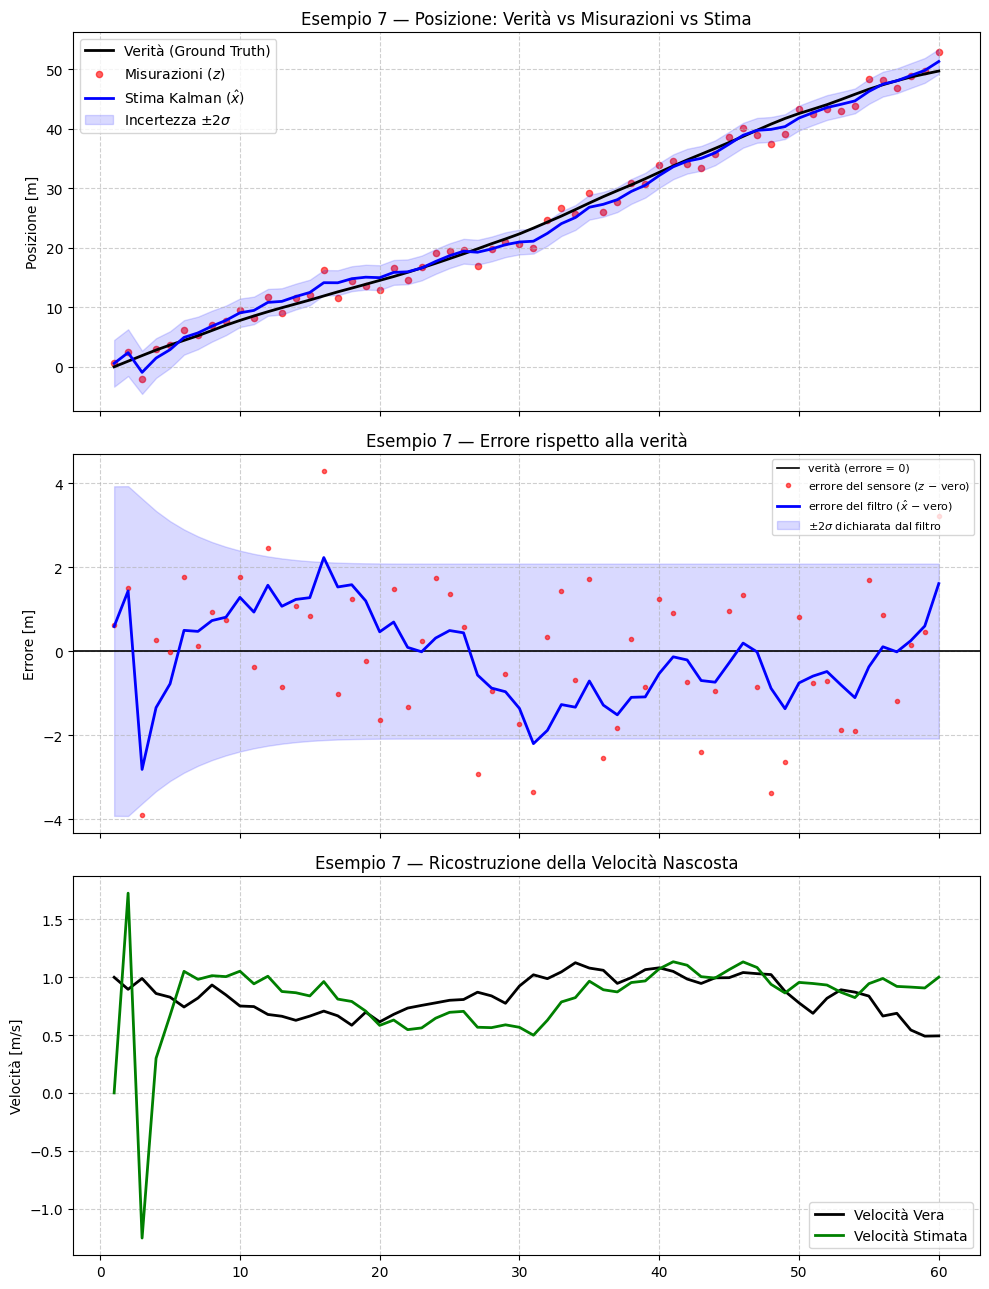

In [62]:
# ==============================================================================
# ESEMPIO 7: Ground Truth, Errore, Banda di Incertezza +-2sigma e Innovazione
# ==============================================================================

rng = np.random.default_rng(seed=42)
N, dt = 60, 1.0
R_true, sigma_a = 4.0, 0.1

# 1. Generazione della Traiettoria Vera (Ground Truth) e Misurazioni Rumorose
pos_true, vel_true, measurements_gt = [], [], []
p, v = 0.0, 1.0  # Posizione e velocità iniziali reali

for k in range(N):
  pos_true.append(p)
  vel_true.append(v)
  measurements_gt.append(p + rng.normal(0.0, sqrt(R_true)))
  a = rng.normal(0.0, sigma_a)
  p += v * dt + 0.5 * a * (dt**2)
  v += a * dt

# 2. Parametrizzazione del Filtro di Kalman
F = matrix([[1.0, dt], [0.0, 1.0]])
H = matrix([[1.0, 0.0]])
R = matrix([[R_true]])
# Q = sigma_a^2 * [[dt^4/4, dt^3/2], [dt^3/2, dt^2]]
Q = matrix([
    [sigma_a**2 * (dt**4 / 4), sigma_a**2 * (dt**3 / 2)],
    [sigma_a**2 * (dt**3 / 2), sigma_a**2 * (dt**2)],
])

x_init = matrix([[0.0], [0.0]])  # Il filtro ipotizza p0 = 0.0 e v0 = 0.0
P_init = matrix([[100.0, 0.0], [0.0, 100.0]])

# 3. Esecuzione del Filtro
res_gt = kalman_filter(measurements_gt, x_init, P_init, F, H, R, Q)

# Estraggo i dati
pos_est = np.array(res_gt['positions'])
vel_est = np.array(res_gt['velocities'])
sigma_p = np.sqrt(res_gt['uncertainties'])

pos_true = np.array(pos_true)
vel_true = np.array(vel_true)
meas_arr = np.array(measurements_gt)

# Innovazione (sorpresa): misura - posizione predetta prima dell'update.
# kalman_filter restituisce solo le stime dopo l'update, quindi ricostruiamo la
# predizione: al passo k e' la stima del passo k-1 spostata con il modello (p + v*dt).
x0 = x_init.value[0][0]
pos_pred = np.concatenate([[x0], pos_est[:-1] + vel_est[:-1] * dt])
innovation = meas_arr - pos_pred


def rmse(a, b):
  return np.sqrt(np.mean((a - b) ** 2))


err_meas = rmse(meas_arr, pos_true)
err_kalman = rmse(pos_est, pos_true)
coverage_2sigma = np.mean(np.abs(pos_true - pos_est) <= 2 * sigma_p) * 100

print(f'RMSE Misure Grezze vs Verità (Posizione): {err_meas:.3f}')
print(f'RMSE Filtro Kalman vs Verità (Posizione): {err_kalman:.3f}')
print(f'Riduzione dell\'Errore:                     {(1 - err_kalman / err_meas) * 100:.1f}%')
print(f'Copertura nella Banda +-2σ:                {coverage_2sigma:.1f}% (Atteso ~95%)')
print(f'Media dell\'innovazione (dal passo 5):      {innovation[4:].mean():+.2f} m (attesa ~0)')

# 4. Visualizzazione Grafica
t = np.arange(1, N + 1)
fig, axs = plt.subplots(3, 1, figsize=(10, 13), sharex=True)

# Grafico (a) Posizione
axs[0].plot(t, pos_true, 'k-', linewidth=2, label='Verità (Ground Truth)')
axs[0].scatter(t, meas_arr, color='red', s=20, alpha=0.6, label='Misurazioni ($z$)')
axs[0].plot(t, pos_est, 'b-', linewidth=2, label='Stima Kalman ($\\hat{x}$)')
axs[0].fill_between(t, pos_est - 2 * sigma_p, pos_est + 2 * sigma_p,
                    color='blue', alpha=0.15, label=r'Incertezza $\pm 2\sigma$')
axs[0].set_title('Esempio 7 — Posizione: Verità vs Misurazioni vs Stima')
axs[0].set_ylabel('Posizione [m]')
axs[0].legend(loc='upper left')
axs[0].grid(True, linestyle='--', alpha=0.6)

# Grafico (b) Errore rispetto alla verità
axs[1].axhline(0, color='black', linewidth=1.2, label='verità (errore = 0)')
axs[1].plot(t, meas_arr - pos_true, 'r.', alpha=0.6, label='errore del sensore ($z$ − vero)')
axs[1].plot(t, pos_est - pos_true, 'b-', linewidth=2, label=r'errore del filtro ($\hat{x}$ − vero)')
axs[1].fill_between(t, -2 * sigma_p, 2 * sigma_p, color='blue', alpha=0.15,
                    label=r'$\pm 2\sigma$ dichiarata dal filtro')
axs[1].set_title('Esempio 7 — Errore rispetto alla verità')
axs[1].set_ylabel('Errore [m]')
axs[1].legend(loc='upper right', fontsize=8)
axs[1].grid(True, linestyle='--', alpha=0.6)

# Grafico (c) Velocità (mai misurata)
axs[2].plot(t, vel_true, 'k-', linewidth=2, label='Velocità Vera')
axs[2].plot(t, vel_est, 'g-', linewidth=2, label='Velocità Stimata')
axs[2].set_title('Esempio 7 — Ricostruzione della Velocità Nascosta')
axs[2].set_ylabel('Velocità [m/s]')
axs[2].legend(loc='lower right')
axs[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# Esercizio Didattico 1: Calibrazione della Matrice R (Fiducia nel Sensore)

## Obiettivo
Comprendere come la matrice di covarianza del rumore di misura $R$ influenzi il bilanciamento del filtro di Kalman tra la fiducia nelle misurazioni del sensore e l'affidabilità del modello fisico di movimento.

## Scenario
Un rover si muove a velocità costante lungo una traiettoria lineare. Per evidenziare il ruolo teorico del parametro $R$, **applichiamo due diverse configurazioni matematiche allo stesso set di misurazioni rumorose**:

1. **Caso A (Ipotesi Sensore LiDAR / Alta Precisione):**  
   Impostiamo una covarianza del rumore molto bassa ($R = 0.05$). Dicendo al filtro che il sensore è estremamente preciso, lo forziamo a **inseguire da vicino ogni singola misurazione**, reclinando la stima verso ogni fluttuazione del sensore.

2. **Caso B (Ipotesi GPS Economico / Bassa Precisione):**  
   Impostiamo una covarianza del rumore molto alta ($R = 25.0$). Dicendo al filtro che la misurazione è poco affidabile, lo forziamo a **fidarsi prevalentemente del modello fisico**, ignorando i picchi accidentali e filtrando il rumore.

---

## Compito
1. Completa la parametrizzazione della matrice $R$ nei due casi (`R_laser` e `R_gps`).
2. Esegui il codice e rispondi alla seguente domanda:
   * **Domanda:** In quale dei due casi la traiettoria stimata dal filtro di Kalman risulta più "morbida" (*smoothing*)? Perché?

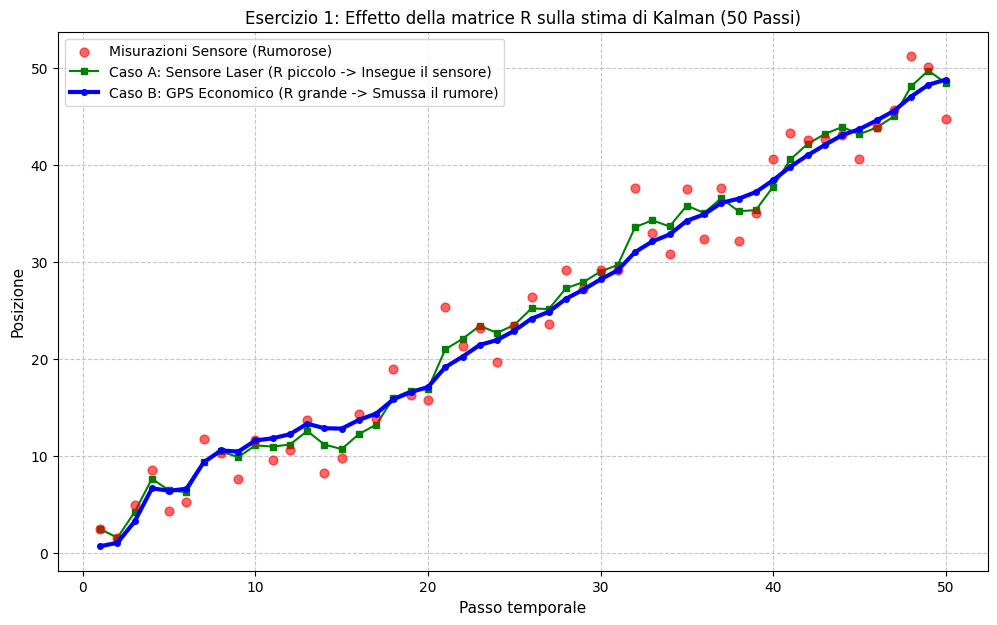

In [65]:
# ==============================================================================
# ESERCIZIO 1: Completare la parametrizzazione di R (50 Iterazioni)
# ==============================================================================
import numpy as np

# Per rendere i risultati riproducibili
np.random.seed(42)

# Misurazioni di posizione estese a 50 passi temporali (con forte rumore)
# Generiamo un trend lineare (1.0, 2.0, ...) con fluttuazioni ed errori casuali
n_steps = 50
trend_reale = np.linspace(1.0, 50.0, n_steps)
rumore_sensore = np.random.normal(0, 3.0, n_steps)  # Rumore gaussiano evidente
measurements_ex1 = (trend_reale + rumore_sensore).tolist()

# Parametri fisici del sistema (dt = 1.0)
x_init = matrix([[0.0], [0.0]])
P_init = matrix([[10.0, 0.0], [0.0, 10.0]])  # Incertezza iniziale moderata
F = matrix([[1.0, 1.0], [0.0, 1.0]])
H = matrix([[1.0, 0.0]])
Q = matrix([[0.001, 0.0], [0.0, 0.001]])     # Modello fisico molto stabile

# --- TODO STUDENTE: Imposta le matrici R per i due sensori ---
# Caso A: Sensore Laser (Rumore basso -> Alta fiducia nel sensore)
R_laser = matrix([[0.00]])  # TODO: Imposta il valore corretto

# Caso B: Sensore GPS Economico (Rumore molto elevato -> Bassa fiducia nel sensore)
R_gps = matrix([[0.0]])    # TODO: Imposta il valore corretto
# -------------------------------------------------------------

# Esecuzione del Filtro
res_laser = kalman_filter(measurements_ex1, x_init, P_init, F, H, R_laser, Q)
res_gps = kalman_filter(measurements_ex1, x_init, P_init, F, H, R_gps, Q)

# Visualizzazione
t = range(1, len(measurements_ex1) + 1)
plt.figure(figsize=(12, 7))

# Misurazioni Sensore
plt.scatter(
    t, measurements_ex1, color='red', s=40, alpha=0.6, zorder=3, label='Misurazioni Sensore (Rumorose)'
)

# Caso A: Laser (R piccolo)
plt.plot(
    t,
    res_laser['positions'],
    'g-s',
    linewidth=1.5,
    markersize=4,
    zorder=2,
    label='Caso A: Sensore Laser (R piccolo -> Insegue il sensore)',
)

# Caso B: GPS (R grande)
plt.plot(
    t,
    res_gps['positions'],
    'b-o',
    linewidth=3.0,
    markersize=4,
    zorder=4,
    label='Caso B: GPS Economico (R grande -> Smussa il rumore)',
)

plt.xlabel('Passo temporale', fontsize=11)
plt.ylabel('Posizione', fontsize=11)
plt.title('Esercizio 1: Effetto della matrice R sulla stima di Kalman (50 Passi)', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

---
## Esercizio  2: Errore nello Stato Iniziale e Ruolo di $\mathbf{P}_0$

###  Obiettivo
Capire come la matrice di covarianza iniziale $\mathbf{P}_0$ permetta al filtro di scartare rapidamente una stima iniziale errata dello stato $\mathbf{x}_0$.

###  Scenario
Un robot parte dalla posizione reale $p = 50.0 \text{ m}$. Tuttavia, la prima stima fornita al filtro è totalmente errata: $\mathbf{x}_0 = \begin{bmatrix} 0 \\ 0 \end{bmatrix}$.

### Compito per lo studente
1. Configura la matrice di incertezza iniziale $\mathbf{P}_0$ impostando varianze molto elevate (es. $10000.0$).
2. Osserva come, già al primo passo di misura ($z_1 \approx 50$), la stima del filtro salti da $0$ a $50$ annullando subito l'errore iniziale.

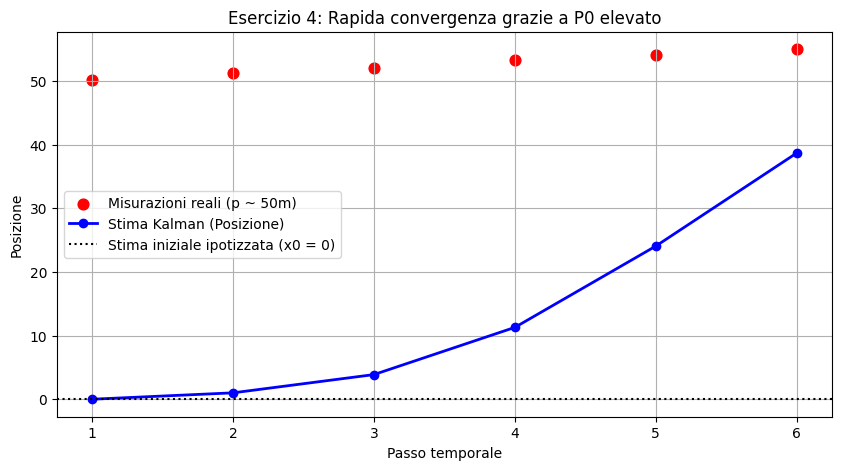

In [66]:
# ==============================================================================
# ESERCIZIO 2: Impostare P0 per superare un errore iniziale di stato
# ==============================================================================

measurements_ex4 = [50.1, 51.2, 52.0, 53.3, 54.1, 55.0]

# Stato iniziale p=0, v=0 (ERRATO!)
x_errato = matrix([[0.0], [0.0]])

# --- TODO STUDENTE: Configura P0 con varianza iniziale elevata ---
P_elevata = matrix(
    [[0.0, 0.0], [0.0, 0.0]] #TODO cambiare questo valore
)
# -----------------------------------------------------------------

F = matrix([[1.0, 1.0], [0.0, 1.0]])
H = matrix([[1.0, 0.0]])
R = matrix([[0.5]])
Q = matrix([[0.01, 0.0], [0.0, 0.01]])

res_ex4 = kalman_filter(
    measurements_ex4, x_errato, P_elevata, F, H, R, Q
)

t = range(1, len(measurements_ex4) + 1)
plt.figure(figsize=(10, 5))
plt.scatter(
    t, measurements_ex4, color='red', s=60, label='Misurazioni reali (p ~ 50m)'
)
plt.plot(
    t, res_ex4['positions'], 'b-o', linewidth=2, label='Stima Kalman (Posizione)'
)
plt.axhline(
    y=0,
    color='black',
    linestyle=':',
    label='Stima iniziale ipotizzata (x0 = 0)',
)
plt.xlabel('Passo temporale')
plt.ylabel('Posizione')
plt.title('Esercizio 4: Rapida convergenza grazie a P0 elevato')
plt.legend()
plt.grid(True)
plt.show()

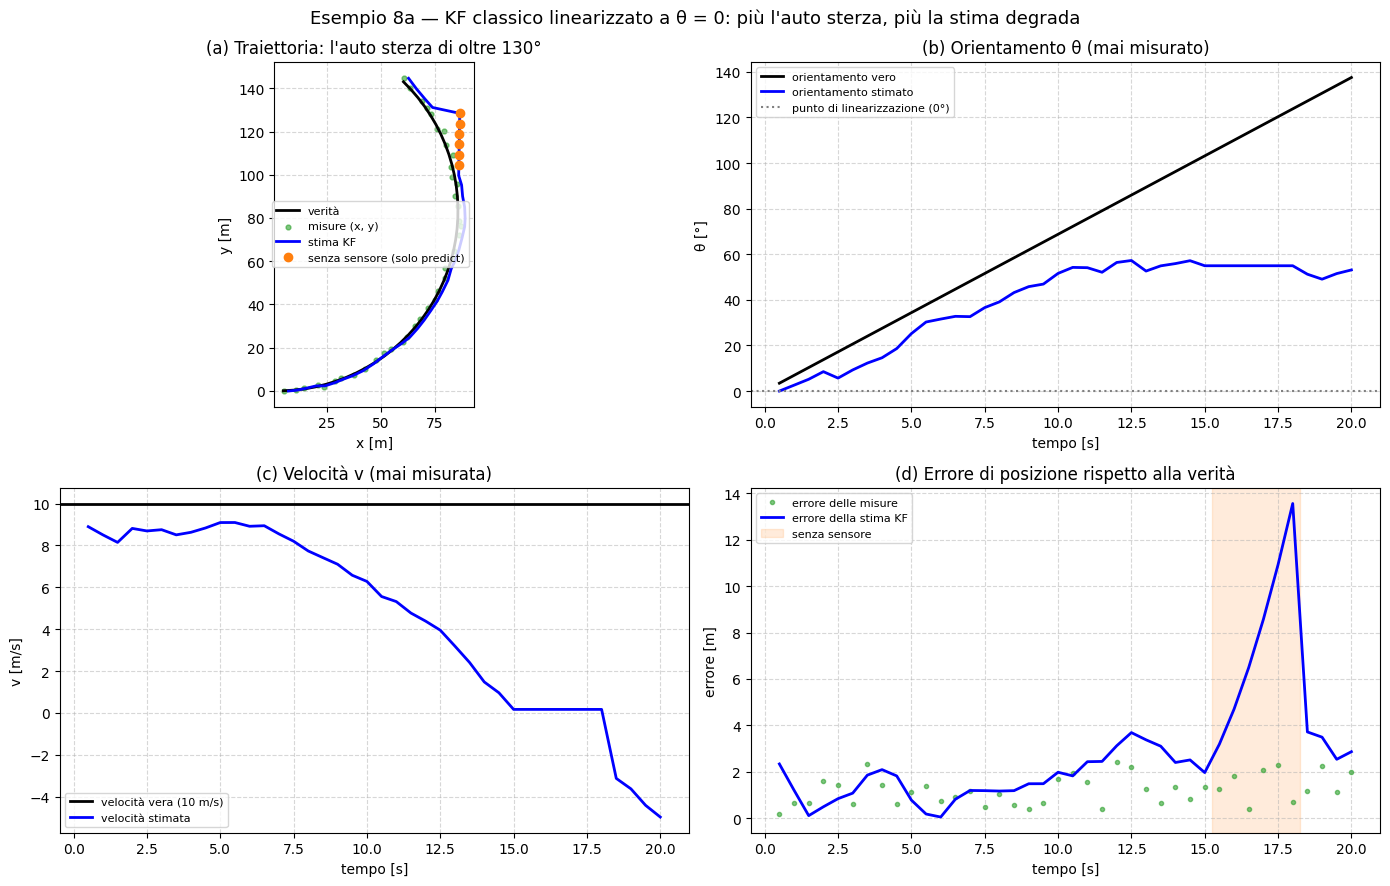

t =  2.5 s   θ vero    17°   θ stimato     6°   v stimata   8.7 m/s   errore posizione 0.8 m
t =  7.5 s   θ vero    52°   θ stimato    37°   v stimata   8.2 m/s   errore posizione 1.2 m
t = 12.5 s   θ vero    86°   θ stimato    57°   v stimata   4.0 m/s   errore posizione 3.7 m
t = 20.0 s   θ vero   138°   θ stimato    53°   v stimata  -5.0 m/s   errore posizione 2.9 m


In [67]:
# ==============================================================================
# ESEMPIO 8a: KF classico con l'orientamento nello stato - un'auto che sterza
# ==============================================================================
# Stato: [x, y, theta, v]. Il moto vero è NON lineare:
#     x' = x + v·dt·cos(theta)        y' = y + v·dt·sin(theta)
# Il KF classico vuole una matrice F fissa, quindi "fotografiamo" il modello
# una volta sola, per theta = 0 e v = 10 m/s (cos 0 = 1, sin theta ≈ theta):
#     x' = x + dt·v                   y' = y + v0·dt·theta
# Funziona finché l'auto va più o meno verso theta = 0. Cosa succede quando sterza?

dt, v0 = 0.5, 10.0
F8 = np.array([[1, 0, 0,       dt],
               [0, 1, v0 * dt, 0 ],
               [0, 0, 1,       0 ],
               [0, 0, 0,       1 ]])
H8 = np.array([[1.0, 0, 0, 0],
               [0, 1.0, 0, 0]])            # il sensore misura solo (x, y)
R8 = np.eye(2) * 1.0                      # rumore del sensore: σ = 1 m
Q8 = np.diag([0.01, 0.01, 0.05**2, 0.2**2])


def simulate_turn(theta0_deg=0.0, omega=0.12, N=40, seed=0):
  """Auto a 10 m/s che sterza con velocità angolare omega [rad/s]."""
  rng = np.random.default_rng(seed)
  p, th = np.zeros(2), np.radians(theta0_deg)
  truth, heading, meas = [], [], []
  for _ in range(N):
    p = p + v0 * dt * np.array([np.cos(th), np.sin(th)])
    th += omega * dt
    truth.append(p.copy()); heading.append(th)
    meas.append(p + rng.normal(0, 1.0, 2))
  return np.array(truth), np.array(heading), np.array(meas)


def kf_linear(meas, gap=None):
  """KF classico con F fissa. gap = (inizio, fine): passi senza misura (solo predict)."""
  x = np.array([meas[0][0], meas[0][1], 0.0, v0])
  P = np.diag([1.0, 1.0, 0.3**2, 1.0])
  X, PP = [], []
  for k, z in enumerate(meas):
    x = F8 @ x
    P = F8 @ P @ F8.T + Q8
    if gap is None or not (gap[0] <= k < gap[1]):
      y = z - H8 @ x
      S = H8 @ P @ H8.T + R8
      K = P @ H8.T @ np.linalg.inv(S)
      x = x + K @ y
      P = (np.eye(4) - K @ H8) @ P
    X.append(x.copy()); PP.append(P.copy())
  return np.array(X), np.array(PP)


truth, heading, meas = simulate_turn()
gap = (30, 36)                                  # 3 secondi senza sensore
X, PP = kf_linear(meas, gap)
t = np.arange(1, len(truth) + 1) * dt
err_kf = np.linalg.norm(X[:, :2] - truth, axis=1)
err_meas = np.linalg.norm(meas - truth, axis=1)

fig, axs = plt.subplots(2, 2, figsize=(14, 9))

# (a) Traiettoria
ax = axs[0, 0]
ax.plot(truth[:, 0], truth[:, 1], 'k-', lw=2, label='verità')
ax.scatter(meas[:, 0], meas[:, 1], s=12, color='tab:green', alpha=0.6, label='misure (x, y)')
ax.plot(X[:, 0], X[:, 1], 'b-', lw=2, label='stima KF')
ax.plot(X[gap[0]:gap[1], 0], X[gap[0]:gap[1], 1], 'o', color='tab:orange', ms=6, label='senza sensore (solo predict)')
ax.set_title('(a) Traiettoria: l\'auto sterza di oltre 130°')
ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]'); ax.set_aspect('equal')
ax.legend(fontsize=8); ax.grid(True, linestyle='--', alpha=0.5)

# (b) Orientamento: vero vs stimato
ax = axs[0, 1]
ax.plot(t, np.degrees(heading), 'k-', lw=2, label='orientamento vero')
ax.plot(t, np.degrees(X[:, 2]), 'b-', lw=2, label='orientamento stimato')
ax.axhline(0, color='gray', ls=':', label='punto di linearizzazione (0°)')
ax.set_title('(b) Orientamento θ (mai misurato)')
ax.set_xlabel('tempo [s]'); ax.set_ylabel('θ [°]')
ax.legend(fontsize=8); ax.grid(True, linestyle='--', alpha=0.5)

# (c) Velocità: vera vs stimata
ax = axs[1, 0]
ax.axhline(v0, color='black', lw=2, label='velocità vera (10 m/s)')
ax.plot(t, X[:, 3], 'b-', lw=2, label='velocità stimata')
ax.set_title('(c) Velocità v (mai misurata)')
ax.set_xlabel('tempo [s]'); ax.set_ylabel('v [m/s]')
ax.legend(fontsize=8); ax.grid(True, linestyle='--', alpha=0.5)

# (d) Errore di posizione
ax = axs[1, 1]
ax.plot(t, err_meas, '.', color='tab:green', alpha=0.6, label='errore delle misure')
ax.plot(t, err_kf, 'b-', lw=2, label='errore della stima KF')
ax.axvspan(t[gap[0]] - dt / 2, t[gap[1] - 1] + dt / 2, color='tab:orange', alpha=0.15, label='senza sensore')
ax.set_title('(d) Errore di posizione rispetto alla verità')
ax.set_xlabel('tempo [s]'); ax.set_ylabel('errore [m]')
ax.legend(fontsize=8); ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('Esempio 8a — KF classico linearizzato a θ = 0: più l\'auto sterza, più la stima degrada', fontsize=13)
plt.tight_layout()
plt.show()

for k in [4, 14, 24, 39]:
  print(f't = {t[k]:4.1f} s   θ vero {np.degrees(heading[k]):5.0f}°   θ stimato {np.degrees(X[k, 2]):5.0f}°   '
        f'v stimata {X[k, 3]:5.1f} m/s   errore posizione {err_kf[k]:.1f} m')